# Tutorial 3 (Introduction to AI)

# Part 2: Support Vector Machines

A Support Vector Machine (SVM) is a type of learning algorithm that performs supervised learning for classification (or regression) of data.

In AI and machine learning, supervised learning systems provide both input and desired output data, which are labeled for classification. The classification provides a learning basis for future data processing. Support vector machines are used to classify data into two groups (extensions for multi-classification exist). The algorithms find lines (hyperplanes) to separate the groups according to patterns.

An SVM builds a learning model that assigns new examples to one group or another. By these functions, SVMs are described as a non-probabilistic, binary linear classifier. 

Like other supervised learning algorithms, an SVM requires labeled data to be trained.  Training data for SVMs are classified separately as different points in space and organized into clearly separated groups. The algorithms try to achieve the best separation of data with the boundary around the hyperplane being maximized and even between both sides.

Here we develop the intuition behind support vector machines and their use in classification problems.

## 1. Introduction

As in Lecture 2, here we will consider  *discriminative classification*, we  find a line or curve (in two dimensions) or manifold/hyperplane (in higher dimensions) that divides the classes from each other.

As an example of this, consider the simple case of a classification task, in which the two classes of points are well separated.

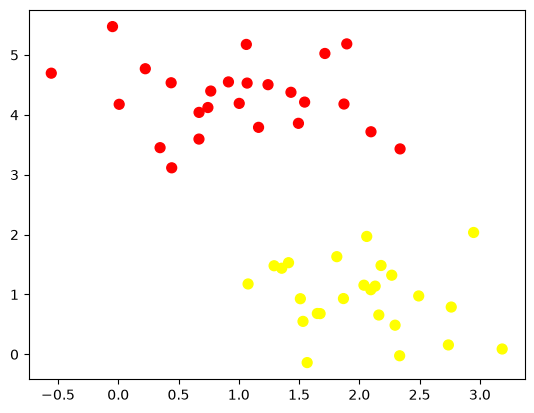

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# FIX: samples_generator was removed from scikit-learn
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn');

A linear discriminative classifier would attempt to draw a straight line separating the two sets of data, and thereby create a model for classification.
For two dimensional data like that shown here, this is a task we could do by hand.
But immediately we see a problem: there is more than one possible dividing line that can perfectly discriminate between the two classes!

We can draw them as follows:

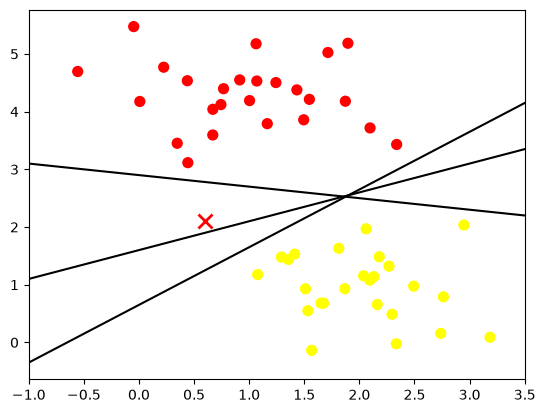

In [2]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.plot([0.6], [2.1], 'x', color='red', markeredgewidth=2, markersize=10)

for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

plt.xlim(-1, 3.5);

These are three *very* different separators which, nevertheless, perfectly discriminate between these samples.
Depending on which you choose, a new data point (e.g., the one marked by the "X" in this plot) will be assigned a different label!
Evidently our simple intuition of "drawing a line between classes" is not enough, and we need to think a bit deeper.

## 2. Margin maximization

Rather than simply drawing a zero-width line between the classes, we can draw around each line a *margin* of some width, up to the nearest point.
Here is an example of how this might look:

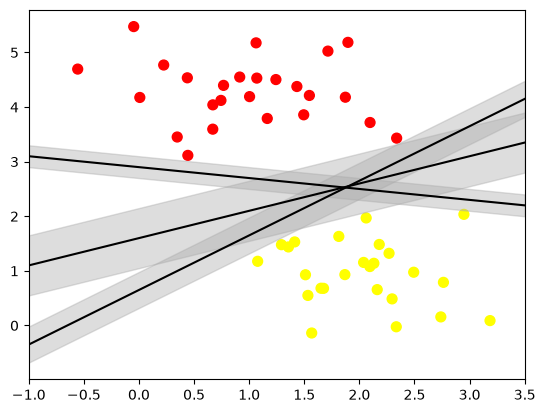

In [3]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5);

In support vector machines, the line that maximizes this margin is the one we will choose as the optimal model.
Support vector machines are an example of such a *maximum margin* estimator.

## 3. Fitting a SVM

Let's see the result of an actual fit to this data: we will use Scikit-Learn's support vector classifier to train an SVM model on this data.

For the time being, we will use a linear kernel and set the ``C`` parameter to a very large number.

In [4]:
from sklearn.svm import SVC # "Support vector classifier"
model = SVC(kernel='linear', C=1E10)
model.fit(X, y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10000000000.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


To better visualize what's happening here, let's create a quick convenience function that will plot SVM decision boundaries for us:

In [5]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    """Plot the decision function for a 2D SVC"""
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    # create grid to evaluate model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)
    
    # plot decision boundary and margins
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])
    
    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none', edgecolors='k');  # FIX: edge colour so the circles are visible
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

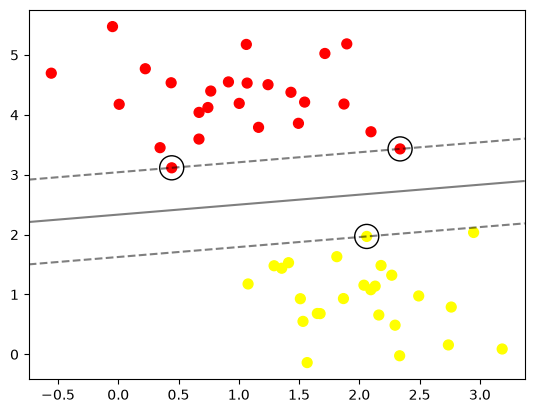

In [6]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model);

This is the dividing line that maximizes the margin between the two sets of points.
Notice that a few of the training points just touch the margin: they are indicated by the black circles in this figure.
These points are the pivotal elements of this fit, and are known as the *support vectors*, and give the algorithm its name.
In Scikit-Learn, the identity of these points are stored in the ``support_vectors_`` attribute of the classifier:

In [7]:
model.support_vectors_

array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

A key to this classifier's success is that for the fit, only the position of the support vectors matter; any points further from the margin which are on the correct side do not modify the fit!
Technically, this is because these points do not contribute to the loss function used to fit the model, so their position and number do not matter so long as they do not cross the margin.

We can see this, for example, if we plot the model learned from the first 60 points and first 120 points of this dataset:

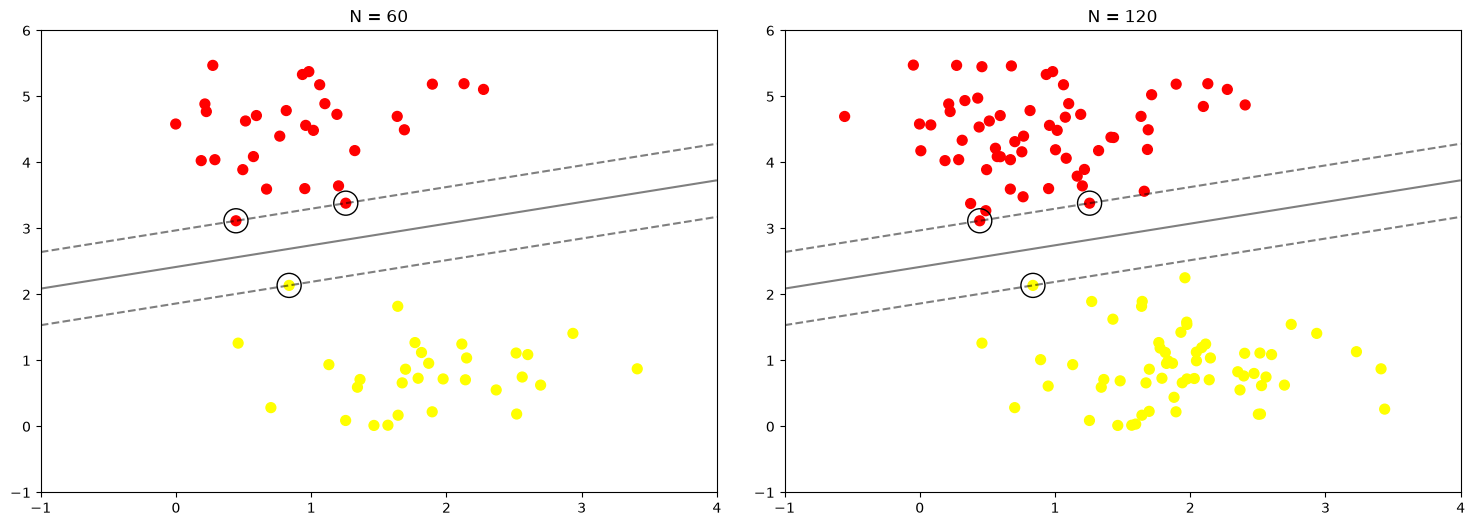

In [8]:
def plot_svm(N=10, ax=None):
    X, y = make_blobs(n_samples=200, centers=2,
                      random_state=0, cluster_std=0.60)
    X = X[:N]
    y = y[:N]
    model = SVC(kernel='linear', C=1E10)
    model.fit(X, y)
    
    ax = ax or plt.gca()
    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model, ax)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))

In the left panel, we see the model and the support vectors for 60 training points.
In the right panel, we have doubled the number of training points, but the model has not changed: the three support vectors from the left panel are still the support vectors from the right panel.
This insensitivity to the exact behavior of distant points is one of the strengths of the SVM model.

If you are running this notebook live, you can use IPython's interactive widgets to view this feature of the SVM model interactively:

In [9]:
from ipywidgets import interact, fixed  # sliders; needs ipywidgets installed
interact(plot_svm, N=[10, 20, 40, 80, 200], ax=fixed(None));

interactive(children=(Dropdown(description='N', options=(10, 20, 40, 80, 200), value=10), Output()), _dom_clas…

## 4. Kernel SVM

Where SVM becomes extremely powerful is when it is combined with *kernels*.

To motivate the need for kernels, let's look at some data that is not linearly separable:

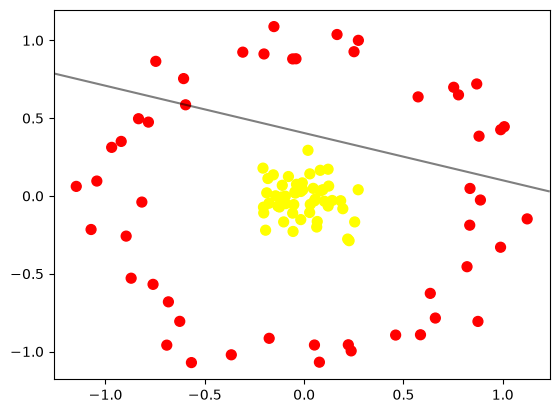

In [10]:
# FIX: samples_generator was removed from scikit-learn
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False);

It is clear that no linear discrimination will *ever* be able to separate this data.

But we can think about how we might project the data into a higher dimension such that a linear separator *would* be sufficient.

For example, one simple projection we could use would be to compute a *radial basis function* centered on the middle clump:

In [11]:
r = np.exp(-(X ** 2).sum(1))

We can visualize this extra data dimension using a three-dimensional plot—if you are running this notebook live, you will be able to use the sliders to rotate the plot:

In [12]:
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed  # FIX: imported here too, so this cell works on its own

def plot_3D(elev=-90, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=(-90, 90), azim=(-180, 180),
         X=fixed(X), y=fixed(y));

interactive(children=(IntSlider(value=-90, description='elev', max=90, min=-90), IntSlider(value=30, descripti…

We can see that with this additional dimension, the data becomes trivially linearly separable, by drawing a separating plane at, say, *r*=0.7.

Here we had to choose and carefully tune our projection: if we had not centered our data in the right location, we would not have seen such clean, linearly separable results.
In general, the need to make such a choice is a problem: we would like to somehow automatically find the best basis functions to use.

One strategy to this end is to compute a basis function centered at *every* point in the dataset, and let the SVM algorithm sift through the results.
This type of basis function transformation is known as a *kernel transformation*, as it is based on a similarity relationship (or kernel) between each pair of points.

A potential problem with this strategy—projecting $N$ points into $N$ dimensions—is that it might become very computationally intensive as $N$ grows large.
However, because of a neat little procedure known as the *kernel trick*, a fit on kernel-transformed data can be done implicitly—that is, without ever building the full $N$-dimensional representation of the kernel projection!
This kernel trick is built into the SVM, and is one of the reasons the method is so powerful.

In Scikit-Learn, we can apply kernelized SVM simply by changing our linear kernel to an RBF (radial basis function) kernel, using the ``kernel`` model hyperparameter:

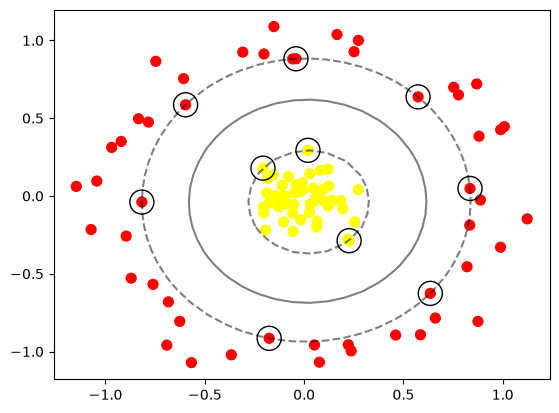

In [13]:
clf = SVC(kernel='rbf', C=1E6, gamma='auto')
clf.fit(X, y)

# ADDED: plot the curved RBF boundary
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)

Using this kernelized support vector machine, we learn a suitable nonlinear decision boundary.
This kernel transformation strategy is used often in machine learning to turn fast linear methods into fast nonlinear methods, especially for models in which the kernel trick can be used.

## 5. Tuning the SVM: Softening Margins

Our discussion thus far has centered around very clean datasets, in which a perfect decision boundary exists.
But what if your data has some amount of overlap?
For example, you may have data like this:

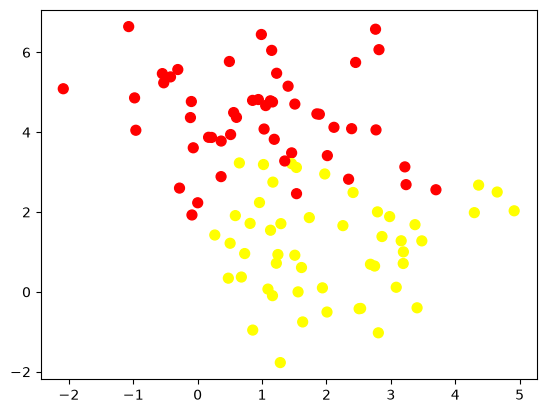

In [14]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=1.2)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn');

To handle this case, the SVM implementation has a bit of a fudge-factor which "softens" the margin: that is, it allows some of the points to creep into the margin if that allows a better fit.
The hardness of the margin is controlled by a tuning parameter, most often known as $C$.
For very large $C$, the margin is hard, and points cannot lie in it.
For smaller $C$, the margin is softer, and can grow to encompass some points.

The plot shown below gives a visual picture of how a changing $C$ parameter affects the final fit, via the softening of the margin:

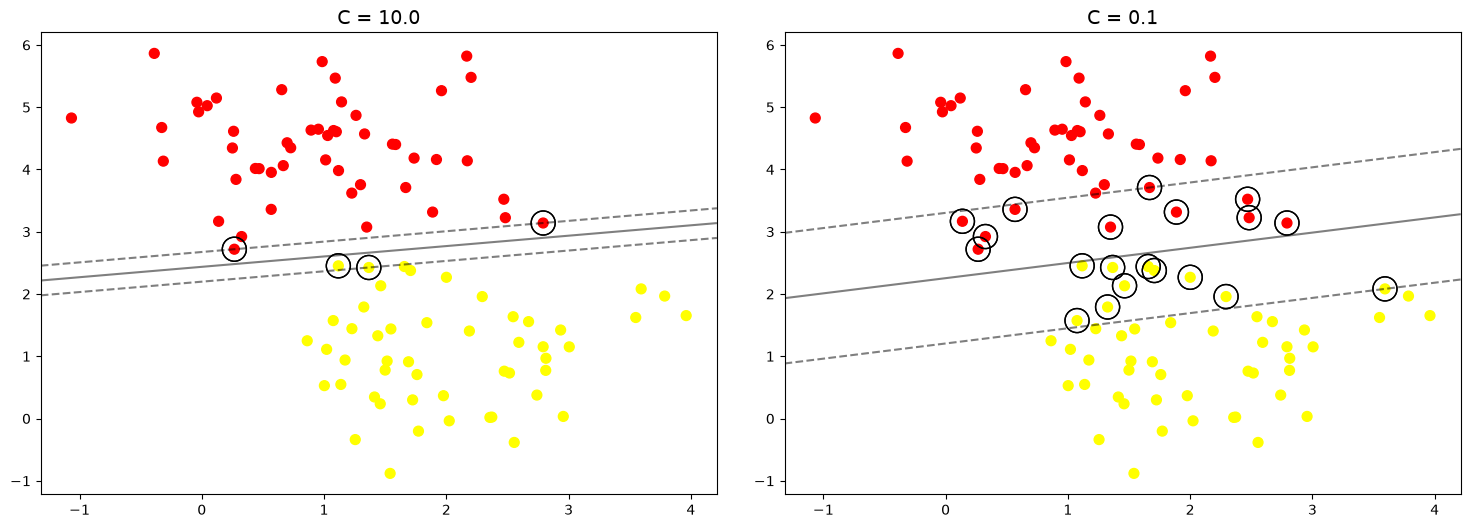

In [15]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:, 0],
                model.support_vectors_[:, 1],
                s=300, lw=1, facecolors='none', edgecolors='k');  # FIX: edge colour so the circles are visible
    axi.set_title('C = {0:.1f}'.format(C), size=14)

The optimal value of the $C$ parameter will depend on your dataset, and should be tuned using cross-validation or a similar procedure.

## 6. Example

Let us return to the *wcbreast_wdbc* dataset to classify if a breast tumour is cancerous (malignant) or not (benign).  Last week we produced a decision-tree classifier for this dataset, this week we shall repeat this process using a SVM.

Again, start by importing datasets and models.

In [16]:
import pandas as pd
import numpy as np

from sklearn import datasets
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

def plot_confusion_matrix(cm, names, title='Confusion matrix', cmap=plt.cm.Blues):
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar(fraction=0.05)
    tick_marks = np.arange(len(names))
    plt.xticks(tick_marks, names, rotation=45)
    plt.yticks(tick_marks, names)
    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

cancer = datasets.load_breast_cancer()

Here, the dataset set is split into training and testing data.

In [17]:
df = pd.DataFrame(data=np.c_[cancer['data'],cancer['target']],
                  columns=np.append(cancer['feature_names'],['target']))

df = df.reindex(np.random.permutation(df.index))

#write out a reminder of the shape of the data
print(df.head())

result = []
for x in df.columns:
    if x != 'target':
        result.append(x)

X = df[result].values
y = df['target'].values
diagnosis = cancer.target_names

#split the dataset, random_state for replication
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42) 

     mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
470        9.667         18.49           61.49      289.1          0.08946   
205       15.120         16.68           98.78      716.6          0.08876   
38        14.990         25.20           95.54      698.8          0.09387   
239       17.460         39.28          113.40      920.6          0.09812   
68         9.029         17.33           58.79      250.5          0.10660   

     mean compactness  mean concavity  mean concave points  mean symmetry  \
470           0.06258         0.02948              0.01514         0.2238   
205           0.09588         0.07550              0.04079         0.1594   
38            0.05131         0.02398              0.02899         0.1565   
239           0.12980         0.14170              0.08811         0.1809   
68            0.14130         0.31300              0.04375         0.2111   

     mean fractal dimension  ...  worst texture  worst perimeter  wo

Now train the SVM using the **fit()** function.  This uses a linear kernal.  You might adjust the C value.

The results are printed, and a normalised confusion matrix given.

Accuracy: 0.94
Confusion matrix, without normalization
[[50  2]
 [ 6 85]]
Normalized confusion matrix
[[0.96 0.04]
 [0.07 0.93]]


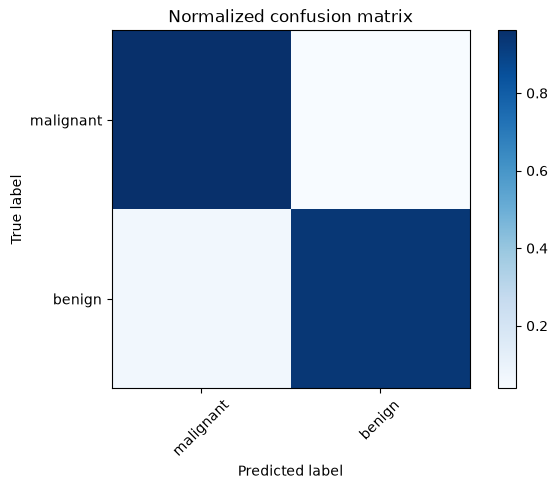

{'C': 100, 'break_ties': False, 'cache_size': 200, 'class_weight': None, 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 'scale', 'kernel': 'linear', 'max_iter': -1, 'probability': 'deprecated', 'random_state': None, 'shrinking': True, 'tol': 0.001, 'verbose': False}


In [18]:
# FIX: train on the training set only (was .fit(X, y), which includes the test rows)
svm_model = SVC(kernel='linear', C=100).fit(X_train, y_train)

y_pred = svm_model.predict(X_test)
#print(y_test)
#print(y_pred)
print('Accuracy: %.2f' % accuracy_score(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
np.set_printoptions(precision=2)
print('Confusion matrix, without normalization')
print(cm)
#normalised confusion matrix
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
print('Normalized confusion matrix')
print(cm_normalized)
plt.figure()
plot_confusion_matrix(cm_normalized, diagnosis, title='Normalized confusion matrix')
plt.show()
print(svm_model.get_params())

## Exercises

1). For an exercise, return to the iris dataset and consider building a SVM for classification.  There are three classes of iris, so a single linear decision won't suffice.  As we have seen, multiclass decision can be made in a number of ways.  The exercise here is to build a SVM for iris classification that uses the one versus one strategy.  To do this work through the following steps:
- import the libraries needed, including *matplotlib.pyplot*
- load the iris dataset and load it into a DataFrame
- split the dataset into *X* (the features) and *y* (the target)
- split the dataset into a training set and a testing set.  For this exercise it is suggested that train_test_split is used for a single split, but a k-fold split might also be used.
- visualise the iris dataset by plotting pairs of feature against each other.  You might use the **scatter** function from pyplot to do this, and **subplot** to collate the nine plots
- build a SVM for multiclassification.  You will need to specify the **decision_function_shape** as **ovo** (one versus one).  See https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html
- fit the model to the training data using **fit**
- calculate the predicted outcomes on the testing data
- print sample out to compare (either simply printing, or by constructing a DataFrame)
- calculate and print some descriptive statistics, such as accuracy
- construct and print a normalised confusion matrix for the outcome

2). The second exercise uses the diabetes dataset from sklearn.  The target here is a number representing progress of the disease.  Is progress predictable from the data using linear regression?
- import the libraries needed, including *matplotlib.pyplot* and *sklearn.linear_model.LinearRegression*
- load the dataset with datasets.load_diabetes()
- you might print some sample data, and note the shape of the data
- split the data into training and test
- fit the linear regression model to the training data
- use this trained model to predict the value for the testing data
- you print out some predictions against actual values  
- calculate the mean and RMSE for test results
- you might consider the correlation between the predictions and the actual results
- plot the predictions versus actual results (with the x=y line down the middle)
- you might also repeat this using a support vector machine for regression  *sklearn.sv.SVR*
- then compare the results for the two approach [in my brief investigation I couldn't get better results with the SVM]

(Final note: I've not investigated the meaning of the dataset carefully.  The results from the above aren't strong.)